# GridWorld baseline: dynamic TOMC + tuned KL-SPMD

**IE 692.** This notebook uses the fixed 10 × 10 GridWorld and a continuous
online trajectory. Each iteration follows:

**Freeze policy → collect until every required pair has at least a 100-term history →
estimate Q from full first-visit suffixes → record value and observations → apply KL-SPMD.**

What is run:

1. **Tuning.** The stepsize $\eta\in\{0.1, 1, 2, 10\}$ is tried with 10% of the observation budget.
2. **Full runs.** The selected $\eta$ is run for 15 million observations on five seeds.
3. **Evaluation.** Every learned policy is evaluated exactly with the Bellman equation,
   and compared with the optimal value $V^*$. The model is used for evaluation only.
4. **Saving.** The curves and wall-clock times are saved to `results/gridworld_baseline.npz`,
   which the enhancement notebooks load for their comparisons.

**How to run:** keep `gridworld_results.py` in the same folder, then run the cells from
top to bottom (about 20 minutes). Dependencies: NumPy, pandas, and Matplotlib.

## 1. Settings and a fixed map

Rows and columns start at zero; state `s = 10 * row + column`. State 0 is the
origin and reporting state. `H` means hazard, `G` goal, `O` origin, and `.`
ordinary cell. Arrays use **[state, action]**.

We use `gamma = 0.9` and `HISTORY_LENGTH = 100` for the minimum history required
before stopping. Each Q estimate uses all costs from its first visit to the common
batch end. Required pairs satisfy `policy[s, a] >= PI_THRESHOLD`, where
`PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS = 0.025`.

A run is limited by **observations, not iterations**: it stops once
`SAMPLE_BUDGET` observations have been collected. The number of observations in
one iteration is determined by collection, so the number of policy updates
that fit in the budget depends on the stepsize and the seed.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator

from gridworld_results import (
    SEEDS, BASELINE_COLOR, INK, MUTED, exact_values, optimal_values, save_runs,
    sample_grid, on_grid, format_mean_ci, apply_plot_style, plot_band, save_figure,
)

GAMMA = 0.9
ETA = 0.1                 # Stepsize for the formula checks; the experiment stepsize is tuned in Section 8.
HISTORY_LENGTH = 100      # MINIMUM history; Q uses the full suffix through the batch end.
SAMPLE_BUDGET = 15_000_000            # Observations in one full run.
TUNING_BUDGET = SAMPLE_BUDGET // 10   # Each tuning run gets 10% of the budget.
ETA_CANDIDATES = (0.1, 1.0, 2.0, 10.0)     # Stepsizes compared in the tuning step.

P_INTENDED = 0.8
Q_MOVE = 0.2              # At a goal/hazard: move with .2, return to origin with .8.
C_GOAL, C_REGULAR, C_HAZARD = 0.0, 0.2, 1.0

LAYOUT = (
    "O........G",
    "..H....H..",
    ".....H....",
    ".H......H.",
    "..........",
    "...H.G....",
    "......H...",
    ".H........",
    "....H...H.",
    ".........G",
)
grid = np.array([list(row) for row in LAYOUT])
N_ROWS, N_COLS = grid.shape
N_STATES, N_ACTIONS = grid.size, 4
PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS
GOALS = set(np.flatnonzero(grid.ravel() == "G"))
HAZARDS = set(np.flatnonzero(grid.ravel() == "H"))
ORIGIN = int(np.flatnonzero(grid.ravel() == "O")[0])
REPORT_STATE = ORIGIN

ACTION_NAMES = ("up", "right", "down", "left")
DIRECTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))

assert grid.shape == (10, 10)
assert len(GOALS) == 3 and len(HAZARDS) == 10
assert np.count_nonzero(grid == "O") == 1
assert ORIGIN not in GOALS | HAZARDS and GOALS.isdisjoint(HAZARDS)

assert 0 <= min(C_GOAL, C_REGULAR, C_HAZARD) <= max(C_GOAL, C_REGULAR, C_HAZARD) <= 1

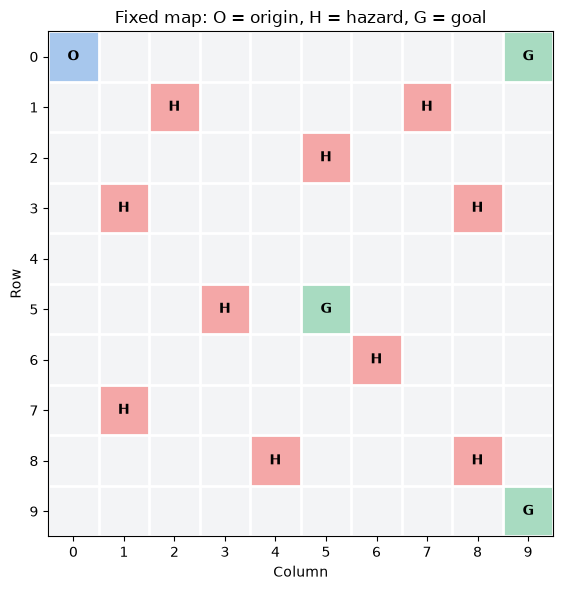

In [2]:
# The colors and letters show the fixed environment, not a learned policy.
colors = {".": 0, "H": 1, "G": 2, "O": 3}
map_colors = np.array([[colors[cell] for cell in row] for row in grid])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(map_colors, cmap=ListedColormap(["#f3f4f6", "#f4a7a7", "#a8dbc1", "#a7c7ed"]),
          vmin=0, vmax=3)
for (row, col), cell in np.ndenumerate(grid):
    if cell != ".":
        ax.text(col, row, cell, ha="center", va="center", fontweight="bold")
ax.set(xticks=range(N_COLS), yticks=range(N_ROWS), xlabel="Column", ylabel="Row",
       title="Fixed map: O = origin, H = hazard, G = goal")
ax.set_xticks(np.arange(-0.5, N_COLS, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N_ROWS, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()


## 2. Environment: give an action, receive (cost, next state)

The environment owns its current state. Ordinary motion follows the intended
direction with probability 0.8 and **each of the other three directions** with
probability $0.2/3$. An attempted move through a wall stays in the same cell.

The cost is charged at the **current state before moving**: goal 0, hazard 1,
ordinary cell (including origin) 0.2. From a goal or hazard, the next step
returns to the origin with probability 0.8; with probability 0.2 it follows
ordinary movement. Thus, entering a hazard does not immediately charge the
hazard cost; the next observation does. Goals and hazards are **not terminal**.

We sample these rules directly; the learner never receives a transition matrix.


In [3]:
def move(state, direction):
    """Attempt one direction; clipping implements the wall rule."""
    row, col = divmod(state, N_COLS)
    dr, dc = DIRECTIONS[direction] #\jm this selects the appropriate coordinate
    row = min(max(row + dr, 0), N_ROWS - 1) #\jm this and line below ensures that the the wall is hit if we go out of boundary, otherwise it is an identity operator
    col = min(max(col + dc, 0), N_COLS - 1)
    return row * N_COLS + col


class GridWorld: #explanation in notes https://drive.google.com/file/d/1RkNBZg5wWsX0OFRMP4xfYPJ41KRbSamP/view?usp=sharing
    def __init__(self):
        self.state = ORIGIN  # Only a new run starts here; policy updates do not reset the state.
        self.move_probs = np.full((N_ACTIONS, N_ACTIONS), (1 - P_INTENDED) / 3) #this creates constant value new array
        np.fill_diagonal(self.move_probs, P_INTENDED)

    def step(self, action, rng): # \jm rm ensures the prob mixing is according to seed. Thats all. Ignore in all of codes.
        """Take one online interaction and return its cost and next state."""
        state = self.state
        cost = C_GOAL if state in GOALS else C_HAZARD if state in HAZARDS else C_REGULAR
        if state in GOALS | HAZARDS and rng.random() < 1 - Q_MOVE:
            next_state = ORIGIN
        else:
            direction = rng.choice(N_ACTIONS, p=self.move_probs[action]) #selects direction using action and policy
            next_state = move(state, direction)
        self.state = next_state #\jm this line makes sure that we start from here when the step function is called instead of intializing their class
        return cost, next_state


## 3. Collect dynamically under a frozen policy

Let $\mathcal E_k=\{(s,a):\pi_k(a\mid s)\ge\underline\pi\}$ and let
$\tau_k(s,a)$ be the first visit index within the current batch, starting at 0.
Collect until

$$n_k=\max_{(s,a)\in\mathcal E_k}\tau_k(s,a)+T,\qquad T=100.$$

Thus every required pair has at least 100 consecutive costs available from
its first visit, and the last required pair discovered has exactly 100.
**The cost at the first visit is term 1: collect 99 more costs after it.**
This does not require 100 visits to that pair. Each required pair uses
**all costs from its first visit through the common batch end**.
Earlier pairs therefore use more than 100 terms; the last required
pair discovered uses exactly 100. Nothing is cut off at term 100.

The policy is frozen throughout collection. The environment continues from
the previous batch's endpoint. All pairs and their first visits are tracked
afresh for each policy. Below-threshold pairs do not delay collection.
There is no observation cap or timeout; rare required pairs can make a batch long.


In [4]:
def required_pair_mask(policy, pi_threshold):
    """Validate a policy and identify the homework's required pairs."""
    policy = np.asarray(policy, dtype=float)
    if policy.ndim != 2 or min(policy.shape) == 0:
        raise ValueError("policy must be a nonempty [state, action] array")
    if not np.isfinite(policy).all() or (policy < 0).any():
        raise ValueError("policy probabilities must be finite and nonnegative")
    if not np.allclose(policy.sum(axis=1), 1.0, rtol=0, atol=1e-12):
        raise ValueError("each policy row must sum to one")
    if not 0 < pi_threshold <= 1 / policy.shape[1]:
        raise ValueError("pi_threshold must be in (0, 1 / number_of_actions]")
    return policy >= pi_threshold


def collect_batch(env, policy, history_length, rng, pi_threshold=PI_THRESHOLD):
    """Stop as soon as the last required first visit has history_length costs."""
    if not isinstance(history_length, (int, np.integer)) or history_length < 1:
        raise ValueError("history_length must be a positive integer")
    required = required_pair_mask(policy, pi_threshold)
    first_visits = np.full(policy.shape, -1, dtype=int)
    missing = int(required.sum())
    states, actions, costs = [int(env.state)], [], []
    stop_after = None

    while stop_after is None or len(costs) < stop_after:
        t = len(costs)
        state = states[-1]
        action = int(rng.choice(policy.shape[1], p=policy[state]))
        cost, next_state = env.step(action, rng)
        actions.append(action)
        costs.append(cost)
        states.append(int(next_state))

        if first_visits[state, action] == -1:
            first_visits[state, action] = t
            if required[state, action]:
                missing -= 1
                if missing == 0:
                    # C_t is already collected: it is the first of T terms.
                    stop_after = t + history_length

    return (np.asarray(states, dtype=int), np.asarray(actions, dtype=int),
            np.asarray(costs, dtype=float))


## 4. Full-history first-visit TOMC estimator

Once collection ends at $n_k$, use each required pair's entire first-visit suffix:

$$\widehat Q_k(s,a)=
\begin{cases}
\displaystyle\sum_{t=\tau_k(s,a)}^{n_k-1}
\gamma^{t-\tau_k(s,a)}C_t,
&\pi_k(a\mid s)\ge\underline\pi,\\[2mm]
\displaystyle\frac{1}{1-\gamma},
&\pi_k(a\mid s)<\underline\pi.
\end{cases}$$

The number of terms is $n_k-\tau_k(s,a)\ge100$ for each required pair.
The immediate cost has weight $\gamma^0=1$. Below-threshold pairs receive
10 when $\gamma=0.9$, even if observed. Repeated visits are counted for
diagnostics; we use one full first-visit return, without averaging or selecting
the smallest observed return.

Compute all suffix returns backward using $G_{n_k}=0$ and
$G_t=C_t+\gamma G_{t+1}$, then take $\widehat Q_k(s,a)=G_{\tau_k(s,a)}$
for required pairs. No available cost is discarded at a 100-term cutoff.
The minimum-history check rejects batches that end too early.


In [5]:
def estimate_q_omc(states, actions, costs, gamma, policy,
                   history_length=HISTORY_LENGTH, pi_threshold=None):
    """Use the entire first-visit suffix; history_length is only a minimum."""
    if not 0 <= gamma < 1:
        raise ValueError("gamma must be in [0, 1)")
    if not isinstance(history_length, (int, np.integer)) or history_length < 1:
        raise ValueError("history_length must be a positive integer")
    if pi_threshold is None:
        pi_threshold = (1 - gamma) / policy.shape[1]
    required = required_pair_mask(policy, pi_threshold)
    states = np.asarray(states, dtype=int)
    actions = np.asarray(actions, dtype=int)
    costs = np.asarray(costs, dtype=float)
    n = len(costs)
    if states.shape != (n + 1,) or actions.shape != (n,) or costs.shape != (n,):
        raise ValueError("expected n+1 states, n actions, and n costs")
    if not np.isfinite(costs).all():
        raise ValueError("costs must be finite")
    n_states, n_actions = policy.shape
    if ((states < 0).any() or (states >= n_states).any()
            or (actions < 0).any() or (actions >= n_actions).any()):
        raise ValueError("state or action index out of range")

    # Independent scan of the recorded trajectory for first visits and counts.
    pair_ids = states[:-1] * n_actions + actions
    visits = np.bincount(pair_ids, minlength=policy.size).reshape(policy.shape)
    first_visits = np.full(policy.size, n, dtype=int)
    np.minimum.at(first_visits, pair_ids, np.arange(n))
    first_visits = first_visits.reshape(policy.shape)
    first_visits[first_visits == n] = -1
    complete = (first_visits >= 0) & (n - first_visits >= history_length)
    if not np.all(complete[required]):
        raise ValueError("a required pair is missing or has an incomplete cost history")

    # Include EVERY recorded cost after a pair's first visit, up to n-1.
    # Backward recursion avoids recomputing overlapping suffixes.
    returns = np.zeros(n + 1, dtype=float)
    for t in range(n - 1, -1, -1):
        returns[t] = costs[t] + gamma * returns[t + 1]

    q_hat = np.full(policy.shape, 1 / (1 - gamma), dtype=float)
    q_hat[required] = returns[first_visits[required]]

    return q_hat, visits, first_visits, required


## 5. KL-SPMD policy update

The KL update is retained. Because we minimize costs,

$$\pi_{k+1}(a\mid s)=
\frac{\pi_k(a\mid s)\exp[-\eta\widehat Q_k(s,a)]}
{\sum_b\pi_k(b\mid s)\exp[-\eta\widehat Q_k(s,b)]},$$

Subtracting the largest exponent in each row improves numerical stability.
The update uses the whole Q table, including the fallback for below-threshold
actions. The collection threshold does not clip, renormalize, or replace the
sampling policy. There is no Tsallis update or exploration mixture.


In [6]:
def kl_spmd_update(policy, q_hat, eta): #directly implementation of class material
    scores = -eta * q_hat
    scores -= scores.max(axis=1, keepdims=True)
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)


## 6. The complete loop and what is recorded

Evaluate the frozen policy $\pi_k$ and record
$\widehat V_k(s_0)=\sum_a\pi_k(a\mid s_0)\widehat Q_k(s_0,a)$ before updating.
Count every environment interaction once, including the 99 interactions after
the last required first visit. Cumulative observations are $\sum_{i=0}^k n_i$.

A new iteration starts only while fewer than `max_observations` observations
have been used, so the last batch may pass the budget. The learning time is
measured with a wall clock and returned as `elapsed_seconds`.

The output keeps evaluated policies, first-visit indices, required-pair masks,
visit counts, Q tables, and the final batch. `min_required_history` must be
100 in each iteration; `max_required_history` records the longest suffix
actually used. Required coverage is 100%; overall coverage can be
lower when some actions fall below the threshold. The environment is
constructed once and carried between iterations.

In [7]:
def run_spmd(max_observations, eta, seed, history_length=HISTORY_LENGTH, gamma=GAMMA,
             report_state=REPORT_STATE, pi_threshold=PI_THRESHOLD, verbose=True):
    """Run dynamic TOMC + KL-SPMD until the observation budget is used."""
    assert max_observations > 0
    assert 0 <= gamma < 1 and eta >= 0 and 0 <= report_state < N_STATES
    rng = np.random.default_rng(seed)
    env = GridWorld()
    policy = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)
    ever_seen = np.zeros_like(policy, dtype=bool)
    records, q_history, visit_history = [], [], []
    first_history, required_history, policy_history = [], [], []
    cumulative_observations = 0
    started = time.perf_counter()

    k = 0
    while cumulative_observations < max_observations:
        batch = collect_batch(env, policy, history_length, rng, pi_threshold)
        states, actions, costs = batch
        q_hat, visits, first_visits, required = estimate_q_omc(
            *batch, gamma, policy, history_length, pi_threshold
        )
        seen = visits > 0
        min_history = int((len(costs) - first_visits[required]).min())
        assert min_history == history_length
        assert len(costs) == first_visits[required].max() + history_length
        ever_seen |= seen
        cumulative_observations += len(costs)
        records.append({
            "iteration": k,
            "value_estimate": float(policy[report_state] @ q_hat[report_state]),
            "observations": len(costs),
            "cumulative_observations": cumulative_observations,
            "pairs_visited": int(seen.sum()),
            "required_pairs": int(required.sum()),
            "fallback_pairs": int((~required).sum()),
            "required_coverage": float(seen[required].mean()),
            "min_required_history": min_history,
            "max_required_history": int((len(costs) - first_visits[required]).max()),
            "coverage": float(seen.mean()),
            "cumulative_coverage": float(ever_seen.mean()),
            "report_actions_seen": int(seen[report_state].sum()),
            "batch_start_state": int(states[0]),
            "batch_end_state": int(states[-1]),
        })
        q_history.append(q_hat)
        visit_history.append(visits)
        first_history.append(first_visits)
        required_history.append(required)
        policy_history.append(policy.copy())
        policy = kl_spmd_update(policy, q_hat, eta)
        k += 1
        if verbose and (k == 1 or k % 10 == 0 or cumulative_observations >= max_observations):
            print(f"eta={eta:g}, seed={seed} | update {k}: {len(costs):,} observations "
                  f"({cumulative_observations:,} in total); {required.sum()} required pairs",
                  flush=True)

    return {"policy": policy, "history": pd.DataFrame(records),
            "eta": eta, "seed": seed,
            "elapsed_seconds": time.perf_counter() - started,
            "q_estimates": np.array(q_history), "visits": np.array(visit_history),
            "first_visits": np.array(first_history),
            "required_pairs": np.array(required_history),
            "evaluated_policies": np.array(policy_history),
            "history_length": history_length, "pi_threshold": pi_threshold,
            "last_batch": batch}

## 7. Small checks before running

Check full-suffix arithmetic (including costs after term 100), discount
exponent zero, a minimum 100-term history with
only one visit to the last required pair, the exact stopping index, threshold
equality, below-threshold fallback even when visited, and rejection of short
histories. The existing KL formula and constant-shift tests follow.


In [8]:
assert move(0, 0) == 0 and move(0, 3) == 0
assert move(99, 1) == 99 and move(99, 2) == 99


def check_dynamic_estimator():
    # Synthetic trajectories isolate estimator arithmetic from the environment.
    pi = np.array([[1., 0., 0., 0.], [0., 1., 0., 0.]])

    class ScriptedEnvironment:
        def __init__(self, costs):
            self.state = 0
            self.costs = costs
            self.calls = 0

        def step(self, action, rng):
            cost = self.costs[self.calls]
            # State 1 is reached once: its action occurs at index 2.
            self.state = 1 if self.calls == 1 else 0
            self.calls += 1
            return cost, self.state

    env = ScriptedEnvironment([0.2, 0.4, 1.0, 0.6, 0.8])
    before = pi.copy()
    batch = collect_batch(env, pi, 3, np.random.default_rng(7))
    q, counts, first, required = estimate_q_omc(*batch, 0.5, pi, 3)
    assert env.calls == 5  # Last first visit at 2, then exactly 3 cost terms.
    # The earlier pair uses all FIVE terms, although the minimum is three.
    np.testing.assert_allclose(q[0, 0],
                               0.2 + 0.5 * 0.4 + 0.5**2 * 1.0
                               + 0.5**3 * 0.6 + 0.5**4 * 0.8)
    np.testing.assert_allclose(q[1, 1], 1.0 + 0.5 * 0.6 + 0.5**2 * 0.8)
    assert counts[0, 0] == 4 and counts[1, 1] == 1
    assert first[0, 0] == 0 and first[1, 1] == 2
    np.testing.assert_allclose(q[~required], 2.0)
    np.testing.assert_array_equal(pi, before)

    for horizon in (1, 100):
        env = ScriptedEnvironment(np.ones(2 + horizon))
        batch = collect_batch(env, pi, horizon, np.random.default_rng(8))
        q, counts, first, required = estimate_q_omc(*batch, GAMMA, pi, horizon)
        assert env.calls == 2 + horizon
        assert counts[1, 1] == 1  # 100 costs is not 100 visits.
        used_lengths = len(batch[2]) - first[required]
        np.testing.assert_allclose(q[required],
                                   (1 - GAMMA**used_lengths) / (1 - GAMMA))
        assert used_lengths.min() == horizon and used_lengths.max() == horizon + 2

    # A positive cost at offset 100 must contribute to an early pair.
    # A fixed-100-term implementation would incorrectly return zero for it.
    late_costs = np.zeros(102)
    late_costs[100] = 1.0
    batch = collect_batch(ScriptedEnvironment(late_costs), pi, 100,
                          np.random.default_rng(9))
    q, *_ = estimate_q_omc(*batch, GAMMA, pi, 100)
    np.testing.assert_allclose(q[0, 0], GAMMA**100, rtol=1e-12, atol=0)
    np.testing.assert_allclose(q[1, 1], GAMMA**98, rtol=1e-12, atol=0)

    # Threshold equality is included; a smaller-probability action uses fallback,
    # even though this recorded trajectory contains that action.
    theta = PI_THRESHOLD
    below = np.nextafter(theta, 0.0)
    edge_pi = np.array([[theta, below, 1 - theta - below, 0.0]])
    edge_states = np.zeros(5, dtype=int)
    edge_actions = np.array([0, 1, 2, 2])
    edge_costs = np.array([0.2, 0.4, 0.6, 0.8])
    q, counts, first, required = estimate_q_omc(
        edge_states, edge_actions, edge_costs, GAMMA, edge_pi, 2, theta
    )
    np.testing.assert_array_equal(required, [[True, False, True, False]])
    np.testing.assert_allclose(q[0, [0, 2]],
                               [0.2 + GAMMA * 0.4 + GAMMA**2 * 0.6 + GAMMA**3 * 0.8,
                                0.6 + GAMMA * 0.8])
    assert counts[0, 1] == 1
    np.testing.assert_allclose(q[0, [1, 3]], 1 / (1 - GAMMA))
    q0, *_ = estimate_q_omc(
        edge_states, edge_actions, edge_costs, 0.0, edge_pi, 2, theta
    )
    np.testing.assert_allclose(q0[0, [0, 2]], [0.2, 0.6])

    # Removing one cost leaves the last required pair with only one of two terms.
    for short_states, short_actions, short_costs in (
        (edge_states[:-1], edge_actions[:-1], edge_costs[:-1]),
        (np.array([0]), np.array([], dtype=int), np.array([])),
    ):
        try:
            estimate_q_omc(short_states, short_actions, short_costs,
                           GAMMA, edge_pi, 2, theta)
        except ValueError:
            pass
        else:
            raise AssertionError("Missing or short required histories must be rejected")

    print("PASS: dynamic stopping, full first-visit suffixes, costs after term 100, threshold, fallback, and short-history rejection.")


check_dynamic_estimator()
test_policy = kl_spmd_update(np.full((2, 4), 0.25),
                             np.array([[0., 1., 2., 3.], [0., 0., 0., 0.]]), ETA)
assert np.allclose(test_policy.sum(axis=1), 1)
assert test_policy[0, 0] > test_policy[0, 3]
assert np.allclose(test_policy[1], 0.25)
print("PASS: walls and KL update direction.")


PASS: dynamic stopping, full first-visit suffixes, costs after term 100, threshold, fallback, and short-history rejection.
PASS: walls and KL update direction.


Test 1: this test checks deterministic policies, zero-probability actions, equal Q-values, normalization, and whether the function accidentally modifies its inputs. None of these, should be able to change the policy and it should remain as we set them.

In [9]:
def check_spmd_formula():
    rng = np.random.default_rng(2026)  # Reproducible test inputs only.
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)
    q = rng.uniform(-3.0, 5.0, size=pi.shape)

    # Also test boundary cases of the probability simplex.
    pi[0] = [0.0, 0.2, 0.3, 0.5]  # One action has zero probability.
    pi[1] = [1.0, 0.0, 0.0, 0.0]  # Deterministic policy.
    q[2] = 2.0                    # All actions have equal Q-values.
    pi_before, q_before = pi.copy(), q.copy()

    for eta in (0.0, ETA, 1.0):
        actual = kl_spmd_update(pi, q, eta)

        # Calculate the formula directly, without numerical stabilization.
        expected = np.empty_like(pi)
        for s in range(N_STATES):
            terms = [pi[s, a] * np.exp(-eta * q[s, a])
                     for a in range(N_ACTIONS)]
            expected[s] = np.array(terms) / sum(terms)

        assert actual.shape == pi.shape
        assert np.isfinite(actual).all() and (actual >= 0).all()
        np.testing.assert_allclose(actual.sum(axis=1), 1.0, atol=1e-12)
        np.testing.assert_allclose(
            actual, expected, rtol=1e-12, atol=1e-12
        )

        # Zero-probability actions remain zero.
        assert np.all(actual[pi == 0] == 0)

        # Equal Q-values leave this state's policy unchanged.
        np.testing.assert_allclose(actual[2], pi[2], atol=1e-12)

        if eta == 0:
            np.testing.assert_allclose(
                actual, pi, rtol=1e-12, atol=1e-12
            )

        # Expected score under the SAME Q-table must not increase.
        old_score = np.sum(pi * q, axis=1)
        new_score = np.sum(actual * q, axis=1)
        assert np.all(new_score <= old_score + 1e-12)

    # The update must not change its input arrays.
    np.testing.assert_array_equal(pi, pi_before)
    np.testing.assert_array_equal(q, q_before)

    print("PASS: nonuniform policies, formula, eta=0, simplex boundaries, and fixed-Q scores.")


check_spmd_formula()

PASS: nonuniform policies, formula, eta=0, simplex boundaries, and fixed-Q scores.


Test 2: Adding \(b(s)\) to every action value at state \(s\) leaves the update unchanged. The factor \(e^{-\eta b(s)}\) cancels between numerator and denominator in the update. This also ensures the probability adds up to 1

In [10]:
def check_spmd_shifts():
    rng = np.random.default_rng(2027)
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)
    q = rng.uniform(-3.0, 5.0, size=pi.shape)
    original = kl_spmd_update(pi, q, ETA)

    # ONE constant per state, shared by that state's actions.
    shifts = [
        rng.uniform(-100.0, 100.0, size=(N_STATES, 1)),
        -np.sum(pi * q, axis=1, keepdims=True),  # Q -> advantage.
        np.full((N_STATES, 1), 10_000.0),
        np.full((N_STATES, 1), -10_000.0),
    ]

    for shift in shifts:
        shifted = kl_spmd_update(pi, q + shift, ETA)
        assert np.isfinite(shifted).all()
        np.testing.assert_allclose(
            shifted, original, rtol=1e-10, atol=1e-12
        )

    print("PASS: row shifts, advantage subtraction, and large common offsets.")


check_spmd_shifts()

PASS: row shifts, advantage subtraction, and large common offsets.


## 8. Exact evaluation of a policy and the optimal value

Build the transition model from the map, independently of the simulator, and
use it **only to measure** the learned policies:

$$V^{\pi}=(I-\gamma P_\pi)^{-1}c,\qquad
V^*(s)=\min_a\Big[c(s)+\gamma\sum_{s'}P(s'\mid s,a)V^*(s')\Big].$$

$V^{\pi_k}(s_0)$ is the actual expected discounted cost of the learned policy
$\pi_k$. The TOMC estimate $\widehat V_k(s_0)$ is a noisy measurement of it.
The distance to the optimum, $V^{\pi_k}(s_0)-V^*(s_0)$, is the optimality gap.

In [11]:
def build_exact_model():
    """Return P[state, action, next_state] and c[state], without move() or GridWorld.step()."""
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    c = np.empty(N_STATES)
    for s in range(N_STATES):
        row, col = divmod(s, N_COLS)
        cell = grid[row, col]
        c[s] = {"G": C_GOAL, "H": C_HAZARD}.get(cell, C_REGULAR)
        special = cell in ("G", "H")
        move_weight = Q_MOVE if special else 1.0
        for a in range(N_ACTIONS):
            if special:
                P[s, a, ORIGIN] += 1.0 - Q_MOVE
            for d, (dr, dc) in enumerate(((-1, 0), (0, 1), (1, 0), (0, -1))):
                r, j = row + dr, col + dc
                inside = 0 <= r < N_ROWS and 0 <= j < N_COLS
                next_s = r * N_COLS + j if inside else s
                probability = P_INTENDED if d == a else (1.0 - P_INTENDED) / 3.0
                P[s, a, next_s] += move_weight * probability
    assert (P >= 0).all()
    np.testing.assert_allclose(P.sum(axis=2), 1.0, atol=1e-12)
    return P, c


P_exact, c_exact = build_exact_model()
V_STAR = optimal_values(P_exact, c_exact, GAMMA)
UNIFORM_POLICY = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)
V_UNIFORM = exact_values(UNIFORM_POLICY, P_exact, c_exact, GAMMA)


def gap_at_report_state(values):
    """Optimality gap at the reporting state for a stack of value vectors [n, state]."""
    return values[:, REPORT_STATE] - V_STAR[REPORT_STATE]


def mean_gap(values):
    """Optimality gap averaged over all 100 start states."""
    return (values - V_STAR).mean(axis=1)


def summarize_run(result):
    """Keep what the comparison plots need: samples, exact values, estimates, and time."""
    history = result["history"]
    policies = np.concatenate([result["evaluated_policies"], result["policy"][None]])
    return {
        "seed": result["seed"],
        # samples[i] observations were used to obtain policy i; policy 0 is uniform.
        "samples": np.concatenate([[0], history["cumulative_observations"]]),
        "values": np.array([exact_values(pi, P_exact, c_exact, GAMMA) for pi in policies]),
        # The last policy is returned but never evaluated by TOMC.
        "estimate": np.append(history["value_estimate"], np.nan),
        "observations": history["observations"].to_numpy(),
        "coverage": history["coverage"].to_numpy(),
        "seconds": result["elapsed_seconds"],
        "final_policy": result["policy"],
    }


print(f"Uniform policy: V(0) = {V_UNIFORM[REPORT_STATE]:.4f}")
print(f"Optimal policy: V*(0) = {V_STAR[REPORT_STATE]:.4f}")
print(f"Largest possible improvement at state 0: {V_UNIFORM[REPORT_STATE] - V_STAR[REPORT_STATE]:.4f}")

Uniform policy: V(0) = 2.3672
Optimal policy: V*(0) = 2.0043
Largest possible improvement at state 0: 0.3629


## 9. Tune the stepsize with 10% of the budget

Each candidate $\eta$ is run once (first seed) with `TUNING_BUDGET` observations.
The score is the exact value at state 0 of the last policy obtained within that
budget. The candidate with the smallest value is used for the full runs.

In [12]:
tuning_rows = []
for eta in ETA_CANDIDATES:
    run = summarize_run(run_spmd(TUNING_BUDGET, eta, SEEDS[0], verbose=False))
    budget = np.array([TUNING_BUDGET])
    tuning_rows.append({
        "eta": eta,
        "policy_updates": int(np.searchsorted(run["samples"], TUNING_BUDGET, side="right") - 1),
        "gap_at_state_0": on_grid(run, budget, gap_at_report_state)[0],
        "mean_gap_all_states": on_grid(run, budget, mean_gap)[0],
        "seconds": run["seconds"],
    })

tuning = pd.DataFrame(tuning_rows)
ETA_TUNED = float(tuning.loc[tuning["gap_at_state_0"].idxmin(), "eta"])
print(f"Tuning budget: {TUNING_BUDGET:,} observations per candidate (seed {SEEDS[0]}).")
print(tuning.round(4).to_string(index=False))
print(f"\nSelected stepsize: eta = {ETA_TUNED:g}")

Tuning budget: 1,500,000 observations per candidate (seed 0).
 eta  policy_updates  gap_at_state_0  mean_gap_all_states  seconds
 0.1               3          0.3474               0.5207  19.4489
 1.0               5          0.1437               0.2129  18.2247
 2.0               2          0.2125               0.2808  18.0641
10.0               1          0.2868               0.3185  21.6919

Selected stepsize: eta = 1


## 10. Full runs on five seeds

Row 0 of each history evaluates the initial uniform policy. Every run starts a
fresh environment at state 0 with its own random generator. The checks confirm
the stopping rule, the fallback entries, and the observation counts of each run.

In [13]:
def check_run(result):
    history = result["history"]
    assert np.allclose(result["policy"].sum(axis=1), 1) and np.all(result["policy"] >= 0)
    np.testing.assert_array_equal(result["visits"].sum(axis=(1, 2)), history["observations"])
    np.testing.assert_array_equal(history["cumulative_observations"],
                                  history["observations"].cumsum())
    assert (history["min_required_history"] == HISTORY_LENGTH).all()
    assert (history["required_coverage"] == 1).all()
    assert np.array_equal(history["batch_start_state"].to_numpy()[1:],
                          history["batch_end_state"].to_numpy()[:-1])
    for k in range(len(history)):
        required = result["required_pairs"][k]
        first = result["first_visits"][k]
        assert history.loc[k, "observations"] == first[required].max() + HISTORY_LENGTH
        np.testing.assert_allclose(result["q_estimates"][k][~required], 1 / (1 - GAMMA))


results = [run_spmd(SAMPLE_BUDGET, ETA_TUNED, seed) for seed in SEEDS]
for result in results:
    check_run(result)
runs = [summarize_run(result) for result in results]

results_path = save_runs(
    "gridworld_baseline", runs,
    eta=ETA_TUNED, gamma=GAMMA, sample_budget=SAMPLE_BUDGET,
    history_length=HISTORY_LENGTH, report_state=REPORT_STATE,
    V_star=V_STAR, V_uniform=V_UNIFORM,
)
print(f"\nSaved {results_path}")

# The inspection and validation cells below use the first seed.
result = results[0]
history = result["history"]

eta=1, seed=0 | update 1: 404,245 observations (404,245 in total); 400 required pairs
eta=1, seed=0 | update 10: 706,822 observations (2,776,200 in total); 357 required pairs
eta=1, seed=0 | update 20: 2,441,365 observations (13,261,654 in total); 324 required pairs
eta=1, seed=0 | update 21: 3,503,790 observations (16,765,444 in total); 321 required pairs
eta=1, seed=1 | update 1: 511,691 observations (511,691 in total); 400 required pairs
eta=1, seed=1 | update 10: 477,949 observations (3,692,248 in total); 359 required pairs
eta=1, seed=1 | update 20: 401,232 observations (8,106,669 in total); 343 required pairs
eta=1, seed=1 | update 27: 2,986,424 observations (15,925,443 in total); 326 required pairs
eta=1, seed=2 | update 1: 467,914 observations (467,914 in total); 400 required pairs
eta=1, seed=2 | update 10: 111,380 observations (2,530,079 in total); 355 required pairs
eta=1, seed=2 | update 20: 288,894 observations (7,229,099 in total); 343 required pairs
eta=1, seed=2 | updat

In [14]:
budget = np.array([SAMPLE_BUDGET])
summary = pd.DataFrame([{
    "seed": run["seed"],
    "policy_updates": len(run["observations"]),
    "observations": int(run["samples"][-1]),
    "learning_seconds": run["seconds"],
    "gap_at_state_0": on_grid(run, budget, gap_at_report_state)[0],
    "mean_gap_all_states": on_grid(run, budget, mean_gap)[0],
} for run in runs])
print(f"KL-SPMD + TOMC, eta = {ETA_TUNED:g}, budget = {SAMPLE_BUDGET:,} observations")
print(summary.round(4).to_string(index=False))
print(f"\nGap at state 0 (mean ± 95% CI): {format_mean_ci(summary['gap_at_state_0'])}")
print(f"Mean gap over all states:       {format_mean_ci(summary['mean_gap_all_states'])}")
print(f"Learning time per run:          {summary['learning_seconds'].mean():.0f} s")

KL-SPMD + TOMC, eta = 1, budget = 15,000,000 observations
 seed  policy_updates  observations  learning_seconds  gap_at_state_0  mean_gap_all_states
    0              21      16765444          200.7965          0.0640               0.1111
    1              27      15925443          187.4693          0.0455               0.0950
    2              32      15652394          191.7088          0.0675               0.1031
    3              21      15649609          185.5892          0.0593               0.1088
    4              28      15270866          180.6138          0.0402               0.0836

Gap at state 0 (mean ± 95% CI): 0.0553 ± 0.0147
Mean gap over all states:       0.1003 ± 0.0139
Learning time per run:          189 s


In [15]:
# Best mean V^pi(0) reached by the baseline, and where. Reads only the saved file.
import numpy as np
import pandas as pd
from gridworld_results import load_runs, on_grid, mean_ci

runs, settings = load_runs("gridworld_baseline")
budget = int(settings["sample_budget"])
state = int(settings["report_state"])
v_star = float(settings["V_star"][state])


def value_at_state(values):
    return values[:, state]


# 1. Mean over seeds. It only changes when some seed updates its policy,
#    so checking every update point (within the budget) finds the exact minimum.
points = np.unique(np.concatenate([run["samples"] for run in runs]))
points = points[points <= budget]
curves = np.array([on_grid(run, points, value_at_state) for run in runs])
mean, half_width = mean_ci(curves)
best = int(np.argmin(mean))
final = len(points) - 1

print(f"V*({state}) = {v_star:.4f}   seeds = {[run['seed'] for run in runs]}   budget = {budget:,}\n")
print(f"Best mean V(0):  {mean[best]:.4f} ± {half_width[best]:.4f}  (gap {mean[best] - v_star:.4f}), "
      f"first reached at {points[best]:,} observations")
print(f"Mean V(0) at the budget: {mean[final]:.4f} ± {half_width[final]:.4f}  (gap {mean[final] - v_star:.4f})\n")

# 2. Best policy of each seed within the budget.
rows = []
for run in runs:
    inside = run["samples"] <= budget
    k = int(np.argmin(run["values"][inside, state]))
    rows.append({"seed": run["seed"], "best_policy_k": k,
                 "observations": int(run["samples"][k]),
                 "V(0)": run["values"][k, state],
                 "gap": run["values"][k, state] - v_star})
print("Best policy of each seed:")
print(pd.DataFrame(rows).round(4).to_string(index=False))

# 3. Observations needed to reach a target gap at state 0 (first time, within the budget).
rows = []
for target in (0.20, 0.10, 0.075, 0.06, 0.05):
    reached = []
    for run in runs:
        inside = run["samples"] <= budget
        hit = np.flatnonzero(run["values"][inside, state] - v_star <= target)
        if hit.size:
            reached.append(run["samples"][hit[0]])
    row = {"target_gap": target, "seeds_reached": f"{len(reached)}/{len(runs)}"}
    if len(reached) >= 2:
        m, h = mean_ci(np.array(reached, dtype=float)[:, None])
        row["observations (mean ± 95% CI)"] = f"{m[0]:,.0f} ± {h[0]:,.0f}"
    elif reached:
        row["observations (mean ± 95% CI)"] = f"{reached[0]:,} (one seed)"
    else:
        row["observations (mean ± 95% CI)"] = "not reached"
    rows.append(row)
print("\nObservations to reach a target gap at state 0:")
print(pd.DataFrame(rows).to_string(index=False))

V*(0) = 2.0043   seeds = [0, 1, 2, 3, 4]   budget = 15,000,000

Best mean V(0):  2.0580 ± 0.0141  (gap 0.0537), first reached at 13,261,654 observations
Mean V(0) at the budget: 2.0596 ± 0.0147  (gap 0.0553)

Best policy of each seed:
 seed  best_policy_k  observations   V(0)    gap
    0             17       7011573 2.0678 0.0635
    1             26      12939019 2.0498 0.0455
    2             14       3877298 2.0627 0.0584
    3             17      10649757 2.0635 0.0593
    4             25      12822101 2.0422 0.0379

Observations to reach a target gap at state 0:
 target_gap seeds_reached observations (mean ± 95% CI)
      0.200           5/5            856,859 ± 436,961
      0.100           5/5          1,835,022 ± 706,611
      0.075           5/5        2,824,794 ± 1,504,538
      0.060           4/5        5,933,462 ± 5,071,882
      0.050           2/5        7,402,539 ± 8,946,676


## 11. Value, observations, and coverage

**Left.** The solid line is the exact value $V^{\pi_k}(s_0)$ of the learned policy,
averaged over seeds, with a 95% confidence band. The dots are the TOMC estimates
$\widehat V_k(s_0)$ of one seed: each is a single first-visit return per action, so
they scatter around the exact value. No running average is used, because it would
average estimates of different policies and lag behind the current one.

**Middle.** Observations in each iteration. A batch ends only after every required
pair has been visited, so it becomes long when the policy rarely reaches some
required pair.

**Right.** Share of state–action pairs visited in each batch. It falls when
actions drop below the probability threshold and switch to the fallback value.

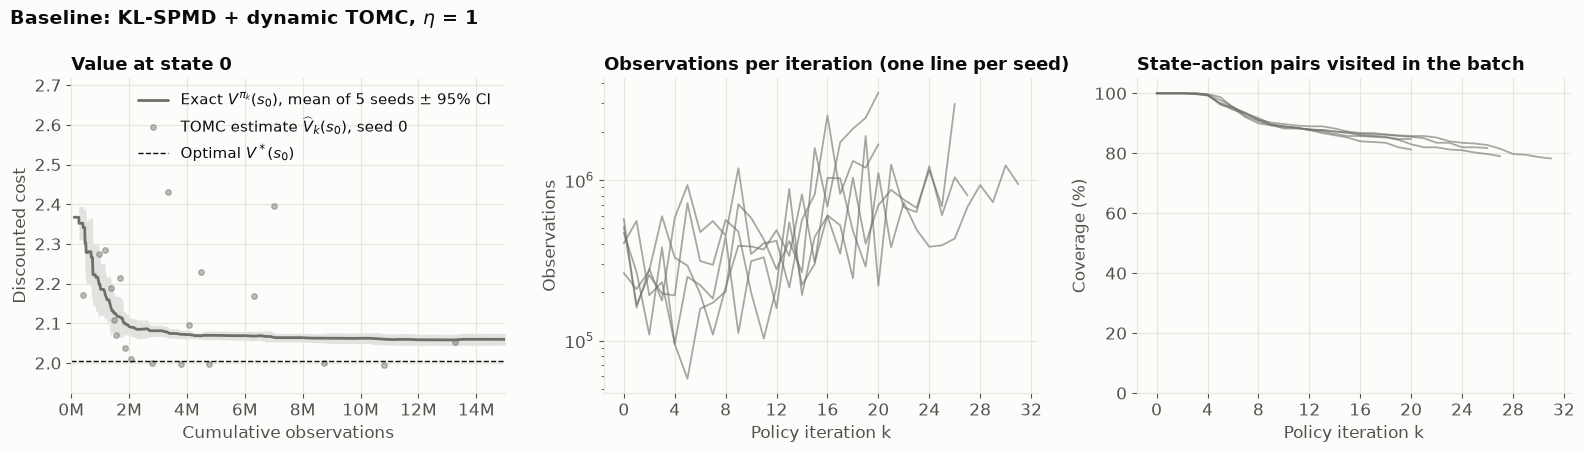

In [16]:
apply_plot_style()
millions = FuncFormatter(lambda x, _: f"{x / 1e6:g}M")
grid_samples = sample_grid(SAMPLE_BUDGET, first=100_000)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
curves = [on_grid(run, grid_samples, lambda v: v[:, REPORT_STATE]) for run in runs]
plot_band(ax, grid_samples, curves, BASELINE_COLOR,
          f"Exact $V^{{\\pi_k}}(s_0)$, mean of {len(runs)} seeds ± 95% CI")
first_run = runs[0]
# Estimate k is known once batch k has ended, at samples[k + 1].
ax.plot(first_run["samples"][1:], first_run["estimate"][:-1], "o", markersize=4,
        color=BASELINE_COLOR, alpha=0.45, label=f"TOMC estimate $\\widehat V_k(s_0)$, seed {first_run['seed']}")
ax.axhline(V_STAR[REPORT_STATE], color=INK, linewidth=1, linestyle="--", label="Optimal $V^*(s_0)$")
ax.set(title="Value at state 0", xlabel="Cumulative observations", ylabel="Discounted cost",
       xlim=(0, SAMPLE_BUDGET), ylim=(V_STAR[REPORT_STATE] - 0.08, V_UNIFORM[REPORT_STATE] + 0.35))
ax.xaxis.set_major_formatter(millions)
ax.legend(loc="upper right")

for run in runs:
    k = np.arange(len(run["observations"]))
    axes[1].plot(k, run["observations"], color=BASELINE_COLOR, alpha=0.6, linewidth=1.3)
    axes[2].plot(k, 100 * run["coverage"], color=BASELINE_COLOR, alpha=0.6, linewidth=1.3)
axes[1].set(title="Observations per iteration (one line per seed)",
            xlabel="Policy iteration k", ylabel="Observations", yscale="log")
axes[2].set(title="State–action pairs visited in the batch",
            xlabel="Policy iteration k", ylabel="Coverage (%)", ylim=(0, 105))
for ax in axes[1:]:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle(f"Baseline: KL-SPMD + dynamic TOMC, $\\eta$ = {ETA_TUNED:g}", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "baseline_results")
plt.show()

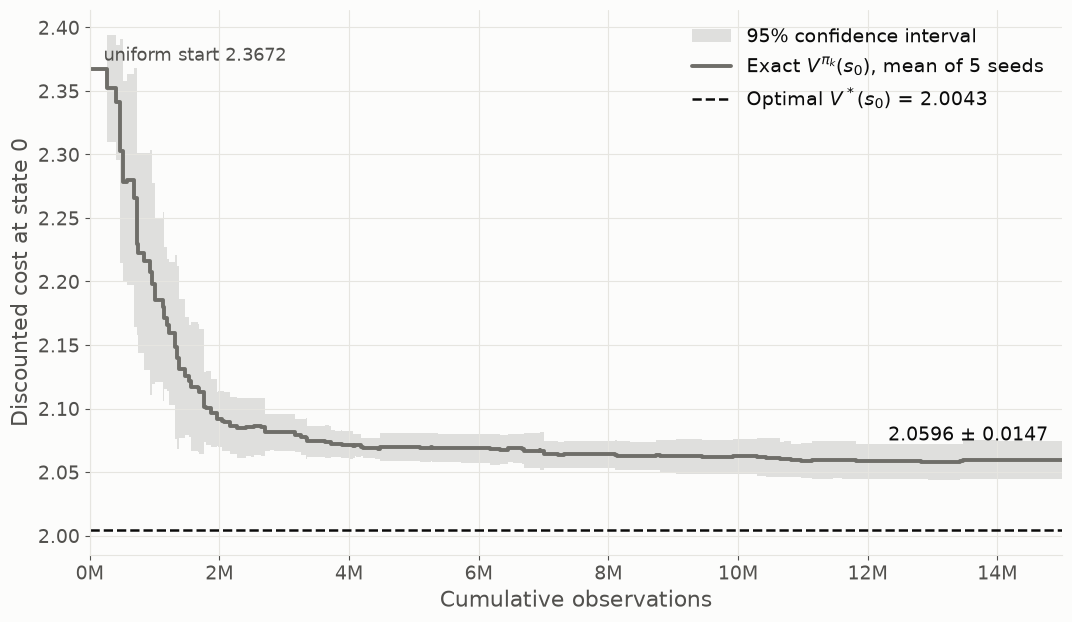

In [20]:
# Large figure: mean exact V^pi(s0) over seeds ± 95% CI, with the optimal V*(s0).
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from gridworld_results import (load_runs, on_grid, mean_ci, apply_plot_style,
                               save_figure, BASELINE_COLOR, INK, MUTED)

runs, settings = load_runs("gridworld_baseline")
budget = int(settings["sample_budget"])
state = int(settings["report_state"])
v_star = float(settings["V_star"][state])
eta = float(settings["eta"])

# Exact step curve: the mean only changes when some seed updates its policy.
points = np.unique(np.concatenate([[0, budget]] + [run["samples"] for run in runs]))
points = points[points <= budget]
curves = np.array([on_grid(run, points, lambda v: v[:, state]) for run in runs])
mean, half_width = mean_ci(curves)

apply_plot_style()
plt.rcParams.update({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16,
                     "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14})
fig, ax = plt.subplots(figsize=(11, 6.5))

ax.fill_between(points, mean - half_width, mean + half_width, step="post",
                color=BASELINE_COLOR, alpha=0.2, linewidth=0, label="95% confidence interval")
ax.step(points, mean, where="post", color=BASELINE_COLOR, linewidth=2.8,
        label=f"Exact $V^{{\\pi_k}}(s_0)$, mean of {len(runs)} seeds")
ax.axhline(v_star, color=INK, linewidth=1.8, linestyle="--",
           label=f"Optimal $V^*(s_0)$ = {v_star:.4f}")

# Label the start and the end of the curve.
ax.annotate(f"{mean[-1]:.4f} ± {half_width[-1]:.4f}", (points[-1], mean[-1]),
            xytext=(-10, 14), textcoords="offset points", ha="right", color=INK, fontsize=14)
ax.annotate(f"uniform start {mean[0]:.4f}", (points[0], mean[0]),
            xytext=(10, 6), textcoords="offset points", color=MUTED, fontsize=13)

ax.set(xlabel="Cumulative observations", ylabel="Discounted cost at state 0", xlim=(0, budget))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:g}M"))
ax.legend(loc="upper right")
fig.tight_layout()
save_figure(fig, "baseline_value_s0")   # figures/baseline_value_s0.png and .pdf
plt.show()

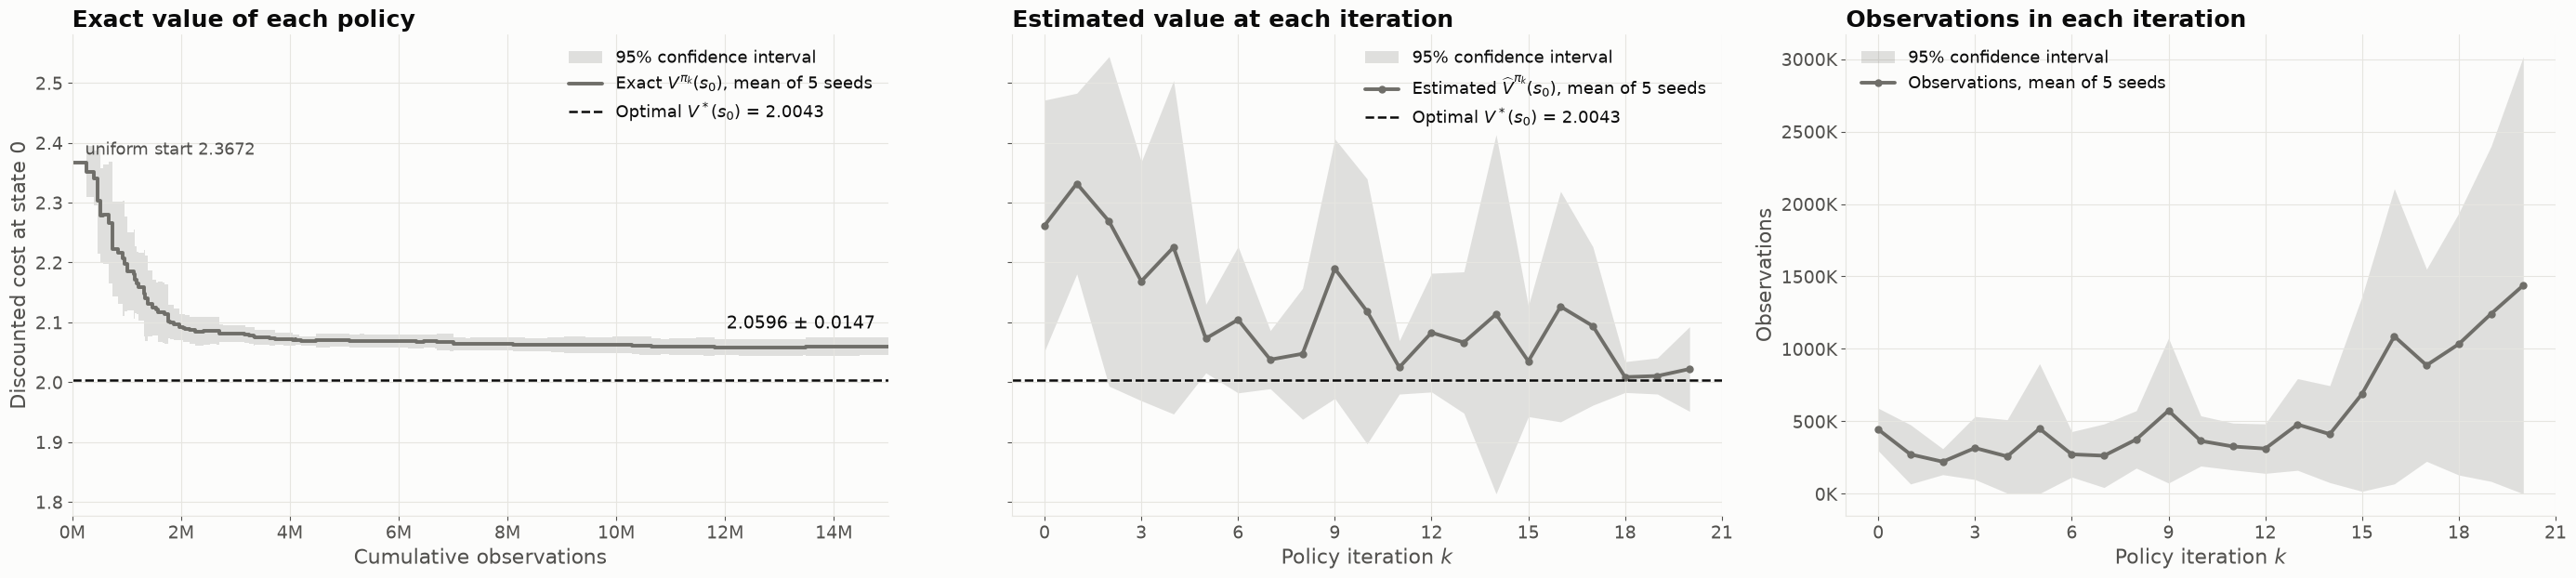

In [23]:
# Three panels: exact V^pi_k(s0) vs observations (left), the TOMC estimate
# V_hat_k(s0) vs policy iteration k (middle), and observations per iteration (right).
# Reads only the saved file.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from gridworld_results import (load_runs, on_grid, mean_ci, apply_plot_style,
                               save_figure, BASELINE_COLOR, INK, MUTED)

runs, settings = load_runs("gridworld_baseline")
budget = int(settings["sample_budget"])
state = int(settings["report_state"])
v_star = float(settings["V_star"][state])

apply_plot_style()
plt.rcParams.update({"font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16,
                     "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13})
fig, (ax, ax_k, ax_n) = plt.subplots(1, 3, figsize=(28, 6.5),
                                     gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax_k.sharey(ax)                      # the two value panels share the y-axis
ax_k.tick_params(labelleft=False)

# ---- Left: exact V^pi_k(s0) against cumulative observations (unchanged) ----
points = np.unique(np.concatenate([[0, budget]] + [run["samples"] for run in runs]))
points = points[points <= budget]
curves = np.array([on_grid(run, points, lambda v: v[:, state]) for run in runs])
mean, half_width = mean_ci(curves)

ax.fill_between(points, mean - half_width, mean + half_width, step="post",
                color=BASELINE_COLOR, alpha=0.2, linewidth=0, label="95% confidence interval")
ax.step(points, mean, where="post", color=BASELINE_COLOR, linewidth=2.8,
        label=f"Exact $V^{{\\pi_k}}(s_0)$, mean of {len(runs)} seeds")
ax.axhline(v_star, color=INK, linewidth=1.8, linestyle="--",
           label=f"Optimal $V^*(s_0)$ = {v_star:.4f}")
ax.annotate(f"{mean[-1]:.4f} ± {half_width[-1]:.4f}", (points[-1], mean[-1]),
            xytext=(-10, 14), textcoords="offset points", ha="right", color=INK, fontsize=14)
ax.annotate(f"uniform start {mean[0]:.4f}", (points[0], mean[0]),
            xytext=(10, 6), textcoords="offset points", color=MUTED, fontsize=13)
ax.set(title="Exact value of each policy", xlabel="Cumulative observations",
       ylabel="Discounted cost at state 0", xlim=(0, budget))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:g}M"))
ax.legend(loc="upper right")

# ---- Middle: estimated V_hat_k(s0) = sum_a pi_k(a|s0) Q_hat_k(s0, a) vs iteration k ----
# run["estimate"][k] is exactly policy[s0] @ q_hat[s0] for iteration k; the last entry
# is NaN because the final policy is never evaluated.
estimates = [run["estimate"][:-1] for run in runs]
n_common = min(len(est) for est in estimates)          # iterations completed by every seed
k_axis = np.arange(n_common)
est_mean, est_half = mean_ci(np.array([est[:n_common] for est in estimates]))

ax_k.fill_between(k_axis, est_mean - est_half, est_mean + est_half,
                  color=BASELINE_COLOR, alpha=0.2, linewidth=0, label="95% confidence interval")
ax_k.plot(k_axis, est_mean, "o-", color=BASELINE_COLOR, linewidth=2.8, markersize=5,
          label=f"Estimated $\\widehat V^{{\\pi_k}}(s_0)$, mean of {len(runs)} seeds")
ax_k.axhline(v_star, color=INK, linewidth=1.8, linestyle="--",
             label=f"Optimal $V^*(s_0)$ = {v_star:.4f}")
ax_k.set(title="Estimated value at each iteration", xlabel="Policy iteration $k$")
ax_k.xaxis.set_major_locator(MaxNLocator(integer=True))
ax_k.legend(loc="upper right")

# ---- Right: observations used in each iteration, same iterations as the middle panel ----
obs_mean, obs_half = mean_ci(np.array([run["observations"][:n_common] for run in runs]))

ax_n.fill_between(k_axis, np.maximum(obs_mean - obs_half, 0), obs_mean + obs_half,
                  color=BASELINE_COLOR, alpha=0.2, linewidth=0, label="95% confidence interval")
ax_n.plot(k_axis, obs_mean, "o-", color=BASELINE_COLOR, linewidth=2.8, markersize=5,
          label=f"Observations, mean of {len(runs)} seeds")
ax_n.set(title="Observations in each iteration", xlabel="Policy iteration $k$",
         ylabel="Observations")
ax_n.xaxis.set_major_locator(MaxNLocator(integer=True))
ax_n.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e3:g}K"))
ax_n.legend(loc="upper left")

fig.tight_layout()
save_figure(fig, "baseline_value_s0_iterations")   # figures/baseline_value_s0_iterations.png and .pdf
plt.show()

## 12. Inspect first visits, history lengths, and fallbacks

Select an iteration and state of the first seed below. `available_cost_terms` counts costs from
the first visit to the batch end; `terms_used_in_Q` equals that available length for required
pairs and is 0 for fallback pairs. Earlier required pairs use longer returns. `visit_count` is a separate diagnostic.
The preview and `result["last_batch"]` contain the final collected trajectory.

In [18]:
iteration_to_inspect = 0
state_to_inspect = REPORT_STATE
idx = (iteration_to_inspect, state_to_inspect)
first = result["first_visits"][idx]
required = result["required_pairs"][idx]
n = int(history.loc[iteration_to_inspect, "observations"])
pair_details = pd.DataFrame({
    "action": ACTION_NAMES,
    "policy_probability": result["evaluated_policies"][idx],
    "Q_estimate": result["q_estimates"][idx],
    "visit_count": result["visits"][idx],
    "first_visit": first,
    "available_cost_terms": np.where(first >= 0, n - first, 0),
    "terms_used_in_Q": np.where(required, n - first, 0),
    "uses_fallback": ~required,
})
print(f"Iteration {iteration_to_inspect}, state {state_to_inspect}:")
print(pair_details.to_string(index=False))

states, actions, costs = result["last_batch"]
observations = pd.DataFrame({"state": states[:-1], "action": actions,
                             "cost": costs, "next_state": states[1:]})
print("\nFirst five observations of the final batch:")
print(observations.head().to_string(index=False))


Iteration 0, state 0:
action  policy_probability  Q_estimate  visit_count  first_visit  available_cost_terms  terms_used_in_Q  uses_fallback
    up                0.25    2.320493        22723           91                404154           404154          False
 right                0.25    2.205324        23003           27                404218           404218          False
  down                0.25    2.069371        23084            0                404245           404245          False
  left                0.25    2.085644        23036            2                404243           404243          False

First five observations of the final batch:
 state  action  cost  next_state
     0       3   0.2           0
     0       2   0.2          10
    10       2   0.2          10
    10       3   0.2          10
    10       3   0.2          10


## 13. Independent Bellman check of a learned policy

Use the exact model of Section 8 and define a comparison table using exact
infinite-horizon $Q^\pi$ for required pairs and the homework fallback for
below-threshold pairs. This separates fallback effects from sampling error.

Full suffixes have different, data-dependent lengths. They omit only costs
beyond the common batch end; no fixed-100-term target is treated as their
exact expectation. Because costs lie in $[0,1]$ and every required suffix has
at least $T=100$ terms, its missing tail is bounded by
$\gamma^T/(1-\gamma)$. The comparison allows for this remaining tail.

Use eight independent dynamic validation batches with the checked policy frozen.
Check full-suffix arithmetic independently for early, middle, and late first
visits and reporting-state actions. Across-batch standard errors describe
Monte Carlo variability; returns within a batch can overlap. The four-standard-
error comparison is a diagnostic, not a guaranteed confidence bound.
Validation observations are reported separately from learning observations.

The checked policy is the one after ten updates of the first seed. It already
has fallback pairs, and its validation batches are still short. A late policy
would need millions of validation observations per batch.

In [19]:
def check_exact_policy(policy, n_batches=8, history_length=HISTORY_LENGTH, seed=2028):
    assert n_batches >= 2
    pi = policy.copy()
    theta = PI_THRESHOLD
    np.testing.assert_allclose(pi.sum(axis=1), 1.0, atol=1e-12)
    assert np.isfinite(pi).all() and (pi >= 0).all()

    P, c = P_exact, c_exact  # Independent model from Section 8.

    # Average transitions over the fixed policy.
    P_pi = np.sum(pi[:, :, None] * P, axis=1)

    # Current-state costs are identical across actions, so c_pi = c.
    V_exact = np.linalg.solve(
        np.eye(N_STATES) - GAMMA * P_pi, c
    )
    Q_exact = c[:, None] + GAMMA * (P @ V_exact)

    # Check the fixed-point equation and V = sum_a pi(a|s) Q(s,a).
    np.testing.assert_allclose(
        V_exact, c + GAMMA * P_pi @ V_exact, atol=1e-11
    )
    np.testing.assert_allclose(
        V_exact, np.sum(pi * Q_exact, axis=1), atol=1e-11
    )



    # Infinite-horizon comparison with the same threshold fallback.
    required = required_pair_mask(pi, theta)
    Q_reference = np.where(required, Q_exact, 1 / (1 - GAMMA))
    V_reference = np.sum(pi * Q_reference, axis=1)
    # A deterministic bound valid despite data-dependent stopping times.
    tail_bound = (GAMMA**history_length / (1 - GAMMA)
                  * np.sum(pi * required, axis=1))

    records, values = [], []
    for b in range(n_batches):
        env = GridWorld()  # Independent validation replicate; no resets within it.
        rng = np.random.default_rng(seed + b)
        batch = collect_batch(env, pi, history_length, rng, theta)
        states, actions, costs = batch
        q_hat, visits, first, required = estimate_q_omc(
            *batch, GAMMA, pi, history_length, theta
        )
        assert visits.sum() == len(costs)
        assert len(costs) == first[required].max() + history_length
        np.testing.assert_array_equal(pi, policy)

        # Forward weighted sums independently verify the backward recursion.
        # Select long, middle, and shortest suffixes plus reporting-state actions.
        pairs = np.argwhere(required)
        pairs = pairs[np.argsort(first[required])]
        check_pairs = {tuple(pairs[i]) for i in (0, len(pairs) // 2, len(pairs) - 1)}
        check_pairs.update((REPORT_STATE, int(a))
                           for a in np.flatnonzero(required[REPORT_STATE]))
        discounts = GAMMA ** np.arange(len(costs))
        for state, action in sorted(check_pairs):
            tau = first[state, action]
            expected = discounts[:len(costs) - tau] @ costs[tau:]
            np.testing.assert_allclose(q_hat[state, action], expected,
                                       rtol=1e-12, atol=1e-12)
        np.testing.assert_allclose(q_hat[~required], 1 / (1 - GAMMA))
        assert (q_hat[required] >= -1e-12).all()
        assert (q_hat[required] <= 1 / (1 - GAMMA) + 1e-12).all()

        v_hat = np.sum(pi * q_hat, axis=1)
        values.append(v_hat)
        records.append({
            "batch": b + 1,
            "observations": len(costs),
            "V_TOMC": v_hat[REPORT_STATE],
            "error_vs_reference": v_hat[REPORT_STATE] - V_reference[REPORT_STATE],
            "coverage": np.mean(visits > 0),
            "min_required_history": int((len(costs) - first[required]).min()),
            "max_required_history": int((len(costs) - first[required]).max()),
        })

    table = pd.DataFrame(records)
    mean_value = table["V_TOMC"].mean()
    standard_error = table["V_TOMC"].std(ddof=1) / np.sqrt(n_batches)
    reference = V_reference[REPORT_STATE]
    lower_reference = reference - tail_bound[REPORT_STATE]
    # The estimator's expectation lies in [reference - tail_bound, reference].
    gap = max(lower_reference - mean_value, mean_value - reference, 0.0)
    tolerance = 4 * standard_error + 1e-10
    print(table.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
    print(f"\nExact infinite-horizon V(state {REPORT_STATE}): {V_exact[REPORT_STATE]:.6f}")
    print(f"Infinite-horizon comparison with fallback: {reference:.6f}")
    print(f"Fallback contribution above exact V: {reference - V_exact[REPORT_STATE]:.6f}")
    print(f"Remaining-tail bound: {tail_bound[REPORT_STATE]:.8f}")
    print(f"Expected full-history estimate lies in [{lower_reference:.6f}, {reference:.6f}]")
    print(f"Mean sampled TOMC: {mean_value:.6f}; batch standard error: {standard_error:.6f}")
    print(f"Gap outside reference interval: {gap:.6f}; diagnostic tolerance: {tolerance:.6f}")
    print(f"Extra validation observations: {table['observations'].sum():,}")
    print("PASS: independent Bellman identities and selected full-suffix arithmetic checks.")
    diagnostic_passed = bool(gap <= tolerance)
    print("PASS: sampled mean agrees with the reference interval within four standard errors."
          if diagnostic_passed else
          "Sampling diagnostic outside four standard errors; increase n_batches to investigate.")

    return {"batches": table, "V_exact": V_exact, "Q_exact": Q_exact,
            "V_reference": V_reference, "tail_bound": tail_bound,
            "mean_V_TOMC": np.mean(values, axis=0),
            "diagnostic_passed": diagnostic_passed}


checked_policy = result["evaluated_policies"][min(10, len(history) - 1)]
validation = check_exact_policy(checked_policy)

 batch  observations   V_TOMC  error_vs_reference  coverage  min_required_history  max_required_history
     1        389055 2.004425           -0.089007  0.890000                   100                389055
     2        191102 2.006024           -0.087408  0.890000                   100                191102
     3        333082 2.014290           -0.079141  0.890000                   100                333082
     4        626891 1.999400           -0.094032  0.892500                   100                626891
     5        430324 2.013165           -0.080267  0.890000                   100                430324
     6        712578 2.016010           -0.077422  0.890000                   100                712578
     7        491469 2.031777           -0.061655  0.890000                   100                491469
     8        459855 2.039195           -0.054237  0.892500                   100                459855

Exact infinite-horizon V(state 0): 2.093432
Infinite-horizon co